# Analyse Comparative de Stocks et ETFs sur le Marché NASDAQ

**Objectif du Projet** :  
Dans ce projet, vous allez analyser des données boursières historiques du dataset `Stock Market Dataset` pour évaluer la performance comparative de stocks et ETFs sélectionnés. L'objectif est de calculer des métriques financières clés (rendements, volatilité, corrélations), de visualiser les tendances et les relations entre actifs, et d'interpréter les résultats dans un contexte économique. Vous utiliserez des structures de données avancées, des classes et dataclasses pour structurer votre analyse, et des visualisations pour appuyer vos conclusions. Ce projet vise à simuler une analyse financière réelle, en mettant l'accent sur l'efficacité du code et l'interprétation économique.

**Prérequis** :  
- Téléchargez et décompressez le dataset dans un dossier local (ex. : `./stock-market-dataset/`).  
- Installez les bibliothèques nécessaires : `pip install pandas seaborn matplotlib numpy`.  
- Sélectionnez 5 stocks (ex. : AAPL, MSFT, GOOGL, AMZN, TSLA) et 3 ETFs (ex. : QQQ, SPY, VTI) pour votre analyse. Assurez-vous que les fichiers CSV correspondants existent dans les dossiers stocks/ et etfs/.  
- Le fil conducteur est le suivant : Commencez par explorer les métadonnées, chargez et préparez les données, analysez les performances individuelles, modélisez avec des classes, explorez les relations entre actifs, visualisez, et concluez avec des insights économiques. Testez votre code étape par étape pour éviter les erreurs cumulatives.


## Section 1 : Exploration des Métadonnées

### Question 1.1 : Chargement du fichier de métadonnées
**Énoncé** :  
Chargez le fichier `symbols_valid_meta.csv` dans un DataFrame Pandas nommé `meta_df`.


In [ ]:
# Insérez votre code ici


**Solution** :


In [ ]:
import pandas as pd

meta_path: str = './stock-market-dataset/symbols_valid_meta.csv'
meta_df: pd.DataFrame = pd.read_csv(meta_path)


### Question 1.2 : Exploration de la structure du DataFrame
**Énoncé** :  
Affichez les 5 premières lignes du DataFrame, les informations sur les colonnes et les types de données, ainsi que les valeurs uniques de la colonne 'Market Category'.


In [30]:
# Insérez votre code ici


**Solution** :


In [31]:
print(meta_df.head())
print(meta_df.info())
print(meta_df['Market Category'].unique())


  Nasdaq Traded Symbol                                      Security Name  \
0             Y      A            Agilent Technologies, Inc. Common Stock   
1             Y     AA                    Alcoa Corporation Common Stock    
2             Y   AAAU                       Perth Mint Physical Gold ETF   
3             Y   AACG  ATA Creativity Global - American Depositary Sh...   
4             Y   AADR                AdvisorShares Dorsey Wright ADR ETF   

  Listing Exchange Market Category ETF  Round Lot Size Test Issue  \
0                N                   N           100.0          N   
1                N                   N           100.0          N   
2                P                   Y           100.0          N   
3                Q               G   N           100.0          N   
4                P                   Y           100.0          N   

  Financial Status CQS Symbol NASDAQ Symbol NextShares  
0              NaN          A             A          N  
1       

### Question 1.3 : Définition des tickers sélectionnés
**Énoncé** :  
Définissez deux listes : `selected_stocks` avec ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA'] et `selected_etfs` avec ['QQQ', 'SPY', 'VTI']. Créez un dictionnaire `category_map` mappant 'Stocks' à la liste des stocks et 'ETFs' à la liste des ETFs.


In [32]:
# Insérez votre code ici


**Solution** :


In [33]:
selected_stocks: list[str] = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA']
selected_etfs: list[str] = ['QQQ', 'SPY', 'VTI']

category_map: dict[str, list[str]] = {'Stocks': selected_stocks, 'ETFs': selected_etfs}


### Question 1.4 : Collecte des exchanges uniques
**Énoncé** :  
Utilisez un set pour collecter les valeurs uniques de la colonne 'Listing Exchange' et stockez-le dans `unique_exchanges`.


In [34]:
# Insérez votre code ici


**Solution** :


In [35]:
unique_exchanges: set[str] = set(meta_df['Listing Exchange'].unique())


### Question 1.5 : Filtrage des métadonnées
**Énoncé** :  
Filtrez le DataFrame pour obtenir uniquement les lignes où 'Symbol' est dans la liste combinée des stocks et ETFs sélectionnés, et stockez-le dans `filtered_meta`.


In [36]:
# Insérez votre code ici


**Solution** :


In [37]:
filtered_meta: pd.DataFrame = meta_df[meta_df['Symbol'].isin(selected_stocks + selected_etfs)]


### Question 1.6 : Calcul de statistiques basiques et affichage
**Énoncé** :  
Calculez des statistiques descriptives sur `filtered_meta` (utilisez `describe()`) et affichez-les. Affichez également les exchanges uniques pour vérifier la cohérence.


In [38]:
# Insérez votre code ici


**Solution** :


In [39]:
print(filtered_meta.describe())
print(f'Exchanges uniques : {unique_exchanges}')


       Round Lot Size
count             8.0
mean            100.0
std               0.0
min             100.0
25%             100.0
50%             100.0
75%             100.0
max             100.0
Exchanges uniques : {'Z', 'A', 'Q', 'N', 'P'}


## Section 2 : Chargement et Préparation des Données

### Question 2.1 : Définition de la fonction de chargement
**Énoncé** :  
Créez une fonction `load_ticker_data(ticker, is_etf=False)` qui charge le CSV correspondant, convertit 'Date' en datetime et index, renomme les colonnes en minuscules sans espaces, et gère l'erreur si le fichier n'existe pas.


In [40]:
# Insérez votre code ici


**Solution** :


In [41]:
import os
from datetime import datetime
import pandas as pd

def load_ticker_data(ticker: str, is_etf: bool = False) -> pd.DataFrame:
    folder: str = 'etfs' if is_etf else 'stocks'
    file_path: str = f'./stock-market-dataset/{folder}/{ticker}.csv'
    if not os.path.exists(file_path):
        raise FileNotFoundError(f'Fichier {ticker}.csv non trouvé dans {folder}.')
    df: pd.DataFrame = pd.read_csv(file_path)
    df['Date'] = pd.to_datetime(df['Date'])
    df.set_index('Date', inplace=True)
    df.columns = [col.lower().replace(' ', '_') for col in df.columns]
    return df


### Question 2.2 : Création des métadonnées des tickers
**Énoncé** :  
Utilisez une liste de dictionnaires `ticker_meta` pour stocker les informations des tickers sélectionnés (chaque dictionnaire avec 'ticker' et 'type' : 'stock' ou 'etf').


In [42]:
# Insérez votre code ici


**Solution** :


In [43]:
ticker_meta: list[dict[str, str]] = [{'ticker': t, 'type': 'stock'} for t in selected_stocks] + [{'ticker': t, 'type': 'etf'} for t in selected_etfs]


### Question 2.3 : Chargement des données des tickers
**Énoncé** :  
Chargez les données pour chaque ticker en utilisant la fonction `load_ticker_data` et stockez-les dans un dictionnaire `data_dict` où les clés sont les tickers.


In [44]:
# Insérez votre code ici


**Solution** :


In [45]:
data_dict: dict[str, pd.DataFrame] = {}
for item in ticker_meta:
    is_etf: bool = item['type'] == 'etf'
    data_dict[item['ticker']] = load_ticker_data(item['ticker'], is_etf)


### Question 2.4 : Concaténation des données
**Énoncé** :  
Concaténez les DataFrames dans `data_dict` en un DataFrame multi-indexé `all_data` (par Date et Ticker), échangez les niveaux des colonnes, triez l'index des colonnes.


In [46]:
# Insérez votre code ici


**Solution** :


In [47]:
all_data: pd.DataFrame = pd.concat(data_dict, axis=1, keys=data_dict.keys())
all_data = all_data.swaplevel(0, 1, axis=1).sort_index(axis=1)


### Question 2.5 : Vérification du format
**Énoncé** :  
Affichez les premières lignes de `all_data` pour confirmer le format.


In [48]:
# Insérez votre code ici


**Solution** :


In [49]:
print(all_data.head())


           adj_close                                      close       ...  \
                AAPL AMZN GOOGL MSFT QQQ SPY TSLA VTI      AAPL AMZN  ...   
Date                                                                  ...   
1980-12-12  0.406782  NaN   NaN  NaN NaN NaN  NaN NaN  0.513393  NaN  ...   
1980-12-15  0.385558  NaN   NaN  NaN NaN NaN  NaN NaN  0.486607  NaN  ...   
1980-12-16  0.357260  NaN   NaN  NaN NaN NaN  NaN NaN  0.450893  NaN  ...   
1980-12-17  0.366103  NaN   NaN  NaN NaN NaN  NaN NaN  0.462054  NaN  ...   
1980-12-18  0.376715  NaN   NaN  NaN NaN NaN  NaN NaN  0.475446  NaN  ...   

           open         volume                                   
           TSLA VTI       AAPL AMZN GOOGL MSFT QQQ SPY TSLA VTI  
Date                                                             
1980-12-12  NaN NaN  117258400  NaN   NaN  NaN NaN NaN  NaN NaN  
1980-12-15  NaN NaN   43971200  NaN   NaN  NaN NaN NaN  NaN NaN  
1980-12-16  NaN NaN   26432000  NaN   NaN  NaN NaN Na

## Section 3 : Analyse Descriptive

### Question 3.1 : Calcul des statistiques pour chaque ticker
**Énoncé** :  
Créez un dictionnaire `stats_dict` où pour chaque ticker (utilisez `all_data.columns.levels[1]`), extrayez le DataFrame du ticker, calculez `describe()` sur 'adj_close', et stockez la série transformée en DataFrame.


In [50]:
# Insérez votre code ici


**Solution** :


In [51]:
import pandas as pd

stats_dict: dict[str, pd.DataFrame] = {}
for ticker in all_data.columns.levels[1]:
    df_ticker: pd.DataFrame = all_data.xs(ticker, level=1, axis=1)
    stats: pd.Series = df_ticker['adj_close'].describe()
    stats_dict[ticker] = stats.to_frame()


### Question 3.2 : Concaténation des statistiques
**Énoncé** :  
Concaténez les statistiques dans un DataFrame `all_stats` et affichez-le.


In [52]:
# Insérez votre code ici


**Solution** :


In [53]:
all_stats: pd.DataFrame = pd.concat(stats_dict, axis=1)
print(all_stats)


              AAPL         AMZN        GOOGL         MSFT          QQQ  \
         adj_close    adj_close    adj_close    adj_close    adj_close   
count  9909.000000  5758.000000  3932.000000  8584.000000  5301.000000   
mean     30.576570   340.417580   509.072183    24.323514    70.837670   
std      56.746275   523.140207   357.153459    30.369640    48.460674   
min       0.155638     1.395833    50.055054     0.057923    17.521547   
25%       0.917643    37.562500   238.697449     2.240606    35.080898   
50%       1.466154    81.599998   327.722733    18.472112    50.280609   
75%      31.042374   334.290001   758.502487    25.608809    97.579445   
max     327.200012  2170.219971  1524.869995   188.185989   236.476059   

               SPY         TSLA          VTI  
         adj_close    adj_close    adj_close  
count  6843.000000  2457.000000  4728.000000  
mean    114.143266   194.344526    70.712499  
std      69.930565   134.449616    36.107205  
min      25.981276    15

### Question 3.3 : Gestion des données manquantes
**Énoncé** :  
Remplissez les valeurs manquantes dans `all_data` avec forward fill.


In [54]:
# Insérez votre code ici


**Solution** :


In [55]:
all_data = all_data.ffill()


### Question 3.4 : Comparaison stocks vs ETFs
**Énoncé** :  
Calculez la moyenne des stats pour les stocks (`stocks_stats`) et les ETFs (`etfs_stats`), concaténez-les dans `comparison` et affichez-le.


In [56]:
# Insérez votre code ici


**Solution** :


In [57]:
stocks_stats: pd.Series = all_stats[selected_stocks].mean(axis=1)
etfs_stats: pd.Series = all_stats[selected_etfs].mean(axis=1)
comparison: pd.DataFrame = pd.concat({'Stocks': stocks_stats, 'ETFs': etfs_stats}, axis=1)
print(comparison)


            Stocks         ETFs
count  6128.000000  5624.000000
mean    219.746875    85.231145
std     220.371839    51.499481
min      13.492890    23.201085
25%      62.797639    49.747616
50%     128.894201    66.582907
75%     284.608735   112.371639
max    1025.579190   248.052378


## Section 4 : Modélisation avec Classes et Dataclasses

### Question 4.1 : Définition de la dataclass
**Énoncé** :  
Définissez une dataclass `FinancialMetric` avec les champs `mean_return: float`, `volatility: float`, et `beta: float = 0.0`.


In [58]:
# Insérez votre code ici


**Solution** :


In [59]:
from dataclasses import dataclass

@dataclass
class FinancialMetric:
    mean_return: float
    volatility: float
    beta: float = 0.0


### Question 4.2 : Définition de la classe AssetAnalyzer - Initialisation et rendements
**Énoncé** :  
Créez une classe `AssetAnalyzer` avec `__init__` prenant `df: pd.DataFrame`, `ticker: str`, `benchmark_df: pd.DataFrame | None = None`. Calculez `self.returns` comme pct_change sur 'adj_close' (dropna).


In [60]:
# Insérez votre code ici


**Solution** :


In [61]:
import numpy as np
import pandas as pd

class AssetAnalyzer:
    def __init__(self, df: pd.DataFrame, ticker: str, benchmark_df: pd.DataFrame | None = None):
        self.df: pd.DataFrame = df
        self.ticker: str = ticker
        self.benchmark: pd.DataFrame | None = benchmark_df
        self.returns: pd.Series = self.df['adj_close'].pct_change().dropna()


### Question 4.3 : Méthodes pour volatilité et rendement moyen
**Énoncé** :  
Ajoutez les méthodes `calculate_volatility(self) -> float` (std * sqrt(252)) et `calculate_mean_return(self) -> float` (mean * 252).


In [62]:
# Insérez votre code ici


**Solution** :


In [74]:
class AssetAnalyzer:
    def __init__(self, df: pd.DataFrame, ticker: str, benchmark_df: pd.DataFrame | None = None):
        self.df: pd.DataFrame = df
        self.ticker: str = ticker
        self.benchmark: pd.DataFrame | None = benchmark_df
        self.returns: pd.Series = self.df['adj_close'].pct_change().dropna()

    def calculate_volatility(self) -> float:
        return self.returns.std() * np.sqrt(252)
    
    def calculate_mean_return(self) -> float:
        return self.returns.mean() * 252


### Question 4.4 : Méthode pour beta
**Énoncé** :  
Ajoutez `calculate_beta(self) -> float` : alignez les rendements, calculez covariance et variance sur les données alignées.


In [64]:
# Insérez votre code ici


**Solution** :


In [75]:
class AssetAnalyzer:
    def __init__(self, df: pd.DataFrame, ticker: str, benchmark_df: pd.DataFrame | None = None):
        self.df: pd.DataFrame = df
        self.ticker: str = ticker
        self.benchmark: pd.DataFrame | None = benchmark_df
        self.returns: pd.Series = self.df['adj_close'].pct_change().dropna()

    def calculate_volatility(self) -> float:
        return self.returns.std() * np.sqrt(252)

    def calculate_mean_return(self) -> float:
        return self.returns.mean() * 252

    def calculate_beta(self) -> float:
        if self.benchmark is None:
            return 0.0
        bench_returns: pd.Series = self.benchmark['adj_close'].pct_change().dropna()
        aligned_df: pd.DataFrame = pd.concat([self.returns, bench_returns], axis=1, join='inner').dropna()
        if len(aligned_df) == 0 or np.var(aligned_df.iloc[:,1]) == 0:
            return 0.0
        cov: float = np.cov(aligned_df.iloc[:,0], aligned_df.iloc[:,1])[0][1]
        var: float = np.var(aligned_df.iloc[:,1])
        return cov / var


### Question 4.5 : Méthode get_metrics
**Énoncé** :  
Ajoutez `get_metrics(self) -> FinancialMetric` retournant une instance de `FinancialMetric` avec les valeurs calculées.


In [66]:
# Insérez votre code ici


**Solution** :


In [76]:
class AssetAnalyzer:
    def __init__(self, df: pd.DataFrame, ticker: str, benchmark_df: pd.DataFrame | None = None):
        self.df: pd.DataFrame = df
        self.ticker: str = ticker
        self.benchmark: pd.DataFrame | None = benchmark_df
        self.returns: pd.Series = self.df['adj_close'].pct_change().dropna()

    def calculate_volatility(self) -> float:
        return self.returns.std() * np.sqrt(252)

    def calculate_mean_return(self) -> float:
        return self.returns.mean() * 252

    def calculate_beta(self) -> float:
        if self.benchmark is None:
            return 0.0
        bench_returns: pd.Series = self.benchmark['adj_close'].pct_change().dropna()
        aligned_df: pd.DataFrame = pd.concat([self.returns, bench_returns], axis=1, join='inner').dropna()
        if len(aligned_df) == 0 or np.var(aligned_df.iloc[:,1]) == 0:
            return 0.0
        cov: float = np.cov(aligned_df.iloc[:,0], aligned_df.iloc[:,1])[0][1]
        var: float = np.var(aligned_df.iloc[:,1])
        return cov / var

    def get_metrics(self) -> FinancialMetric:
        return FinancialMetric(
            mean_return=self.calculate_mean_return(),
            volatility=self.calculate_volatility(),
            beta=self.calculate_beta()
        )


### Question 4.6 : Sélection du benchmark
**Énoncé** :  
Sélectionnez le benchmark comme le DataFrame de 'SPY' si disponible dans `all_data`.


In [77]:
# Insérez votre code ici


**Solution** :


In [78]:
benchmark: pd.DataFrame | None = all_data.xs('SPY', level=1, axis=1) if 'SPY' in all_data.columns.levels[1] else None


### Question 4.7 : Instanciation des analyzers
**Énoncé** :  
Créez un dictionnaire `analyzers` avec une instance d'`AssetAnalyzer` pour chaque ticker.


In [79]:
# Insérez votre code ici


**Solution** :


In [80]:
analyzers: dict[str, AssetAnalyzer] = {}
for ticker in all_data.columns.levels[1]:
    df_ticker: pd.DataFrame = all_data.xs(ticker, level=1, axis=1)
    analyzers[ticker] = AssetAnalyzer(df_ticker, ticker, benchmark)


### Question 4.8 : Affichage des métriques
**Énoncé** :  
Affichez les métriques pour chaque ticker pour vérifier les calculs.


In [81]:
# Insérez votre code ici


**Solution** :


In [82]:
for ticker, analyzer in analyzers.items():
    print(f'{ticker}: {analyzer.get_metrics()}')


AAPL: FinancialMetric(mean_return=np.float64(0.26831882974707294), volatility=np.float64(0.45615081546838987), beta=np.float64(1.0863125261543904))
AMZN: FinancialMetric(mean_return=np.float64(0.47384604127863333), volatility=np.float64(0.5932476339200791), beta=np.float64(1.28514567538398))
GOOGL: FinancialMetric(mean_return=np.float64(0.2441901086919464), volatility=np.float64(0.3050543893124768), beta=np.float64(0.9537126631047509))
MSFT: FinancialMetric(mean_return=np.float64(0.28772794017759046), volatility=np.float64(0.34180725356675595), beta=np.float64(1.0937820647944088))
QQQ: FinancialMetric(mean_return=np.float64(0.10610415815608949), volatility=np.float64(0.2801208539839302), beta=np.float64(1.1873652218016297))
SPY: FinancialMetric(mean_return=np.float64(0.10007664401673137), volatility=np.float64(0.18803171781163924), beta=np.float64(1.0001461774594358))
TSLA: FinancialMetric(mean_return=np.float64(0.45454407702142924), volatility=np.float64(0.542549333055472), beta=np.fl

## Section 5 : Calculs Avancés

### Question 5.1 : Création du DataFrame des rendements
**Énoncé** :  
Créez un DataFrame `returns_df` en concaténant les rendements de chaque analyzer.


In [83]:
# Insérez votre code ici


**Solution** :


In [84]:
import pandas as pd

returns_df: pd.DataFrame = pd.concat([analyzers[t].returns for t in analyzers], axis=1, keys=analyzers.keys())


### Question 5.2 : Calcul de la matrice de corrélations
**Énoncé** :  
Calculez la matrice de corrélations `corr_matrix` sur `returns_df` et affichez-la.


In [85]:
# Insérez votre code ici


**Solution** :


In [86]:
corr_matrix: pd.DataFrame = returns_df.corr()
print(corr_matrix)


           AAPL      AMZN     GOOGL      MSFT       QQQ       SPY      TSLA  \
AAPL   1.000000  0.302492  0.493265  0.412666  0.624054  0.458932  0.280281   
AMZN   0.302492  1.000000  0.479307  0.385643  0.556130  0.430988  0.293115   
GOOGL  0.493265  0.479307  1.000000  0.515390  0.686272  0.604110  0.293915   
MSFT   0.412666  0.385643  0.515390  1.000000  0.711788  0.650920  0.296037   
QQQ    0.624054  0.556130  0.686272  0.711788  1.000000  0.836241  0.420595   
SPY    0.458932  0.430988  0.604110  0.650920  0.836241  1.000000  0.385813   
TSLA   0.280281  0.293115  0.293915  0.296037  0.420595  0.385813  1.000000   
VTI    0.581505  0.488630  0.606861  0.720225  0.887895  0.989420  0.397379   

            VTI  
AAPL   0.581505  
AMZN   0.488630  
GOOGL  0.606861  
MSFT   0.720225  
QQQ    0.887895  
SPY    0.989420  
TSLA   0.397379  
VTI    1.000000  


### Question 5.3 : Identification des paires corrélées
**Énoncé** :  
Unstackez la matrice absolue, triez descendant, supprimez les doublons, et affichez les 10 premières paires (`high_corr`).


In [87]:
# Insérez votre code ici


**Solution** :


In [88]:
high_corr: pd.Series = corr_matrix.abs().unstack().sort_values(ascending=False).drop_duplicates()
print(high_corr.head(10))


AAPL  AAPL     1.000000
VTI   SPY      0.989420
      QQQ      0.887895
SPY   QQQ      0.836241
VTI   MSFT     0.720225
MSFT  QQQ      0.711788
QQQ   GOOGL    0.686272
SPY   MSFT     0.650920
AAPL  QQQ      0.624054
VTI   GOOGL    0.606861
dtype: float64


### Question 5.4 : Définition de la fonction Sharpe
**Énoncé** :  
Définissez une fonction `sharpe_ratio(mean_ret, vol, risk_free=0.0)` retournant (mean_ret - risk_free) / vol.


In [89]:
# Insérez votre code ici


**Solution** :


In [90]:
def sharpe_ratio(mean_ret: float, vol: float, risk_free: float = 0.0) -> float:
    return (mean_ret - risk_free) / vol


### Question 5.5 : Calcul et tri des ratios Sharpe
**Énoncé** :  
Créez un DataFrame `sharpe_df` avec 'Ticker' et 'Sharpe', triez descendant par 'Sharpe', et affichez-le.


In [91]:
# Insérez votre code ici


**Solution** :


In [92]:
sharpe_df: pd.DataFrame = pd.DataFrame({
    'Ticker': [t for t in analyzers],
    'Sharpe': [sharpe_ratio(analyzers[t].get_metrics().mean_return, analyzers[t].get_metrics().volatility) for t in analyzers]
}).sort_values('Sharpe', ascending=False)
print(sharpe_df)


  Ticker    Sharpe
3   MSFT  0.841784
6   TSLA  0.837793
2  GOOGL  0.800481
1   AMZN  0.798732
0   AAPL  0.588224
5    SPY  0.532233
7    VTI  0.411079
4    QQQ  0.378780


## Section 6 : Visualisations

### Question 6.1 : Heatmap des corrélations
**Énoncé** :  
Créez un heatmap Seaborn de `corr_matrix` avec annotations, cmap='coolwarm', taille (10,8), titre 'Matrice de Corrélations des Rendements'.


In [93]:
# Insérez votre code ici


**Solution** :


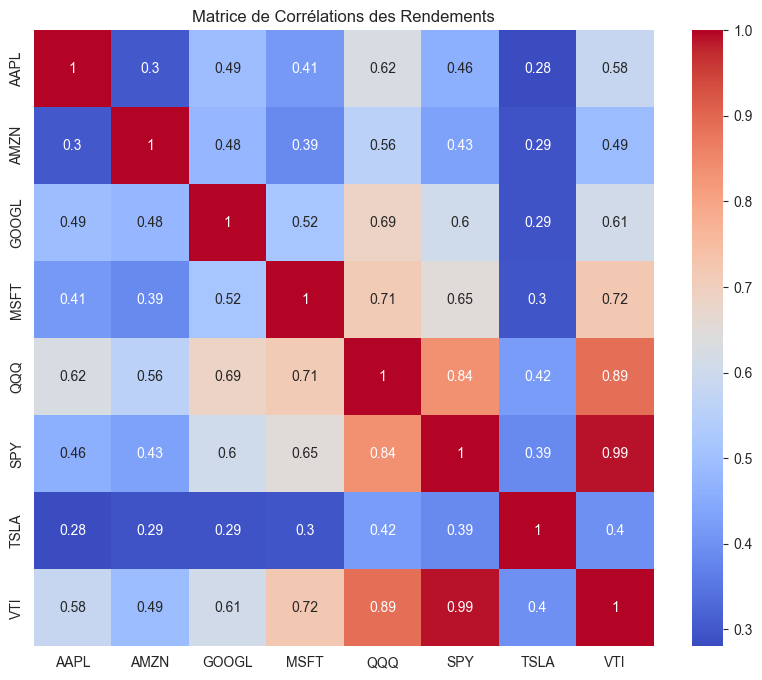

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matrice de Corrélations des Rendements')
plt.show()


### Question 6.2 : Lineplots des prix normalisés
**Énoncé** :  
Normalisez les 'adj_close' en divisant chaque colonne par sa première valeur non-NaN pour gérer les dates de début différentes, plottez avec taille (12,6), titre 'Évolution Normalisée des Prix Ajustés'.


In [ ]:
# Insérez votre code ici


**Solution** :


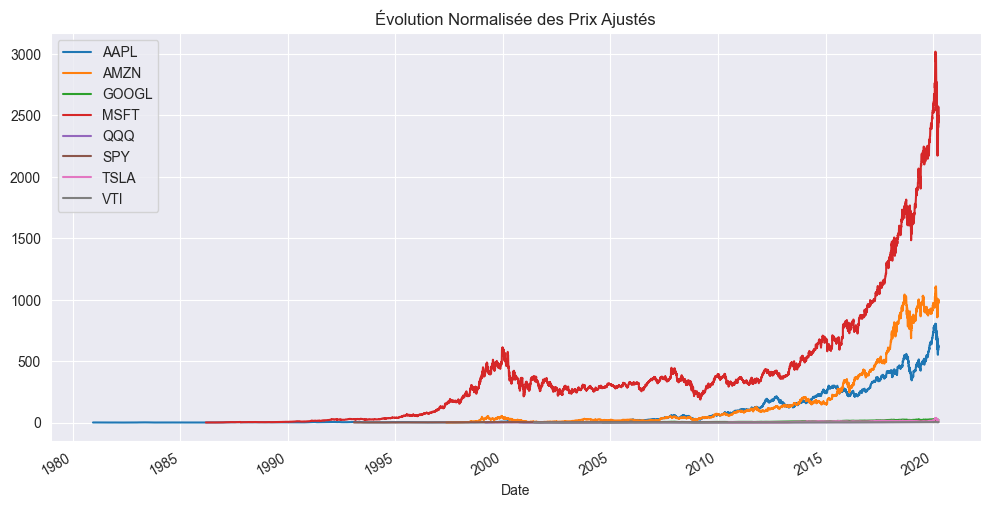

In [116]:
adj_closes: pd.DataFrame = all_data.xs('adj_close', level=0, axis=1)
first_values: pd.Series = adj_closes.apply(lambda col: col.dropna().iloc[0] if not col.dropna().empty else np.nan)
normalized: pd.DataFrame = adj_closes.div(first_values)
normalized.plot(figsize=(12, 6))
plt.title('Évolution Normalisée des Prix Ajustés')
plt.show()


### Question 6.3 : Scatterplot volatilité vs rendement
**Énoncé** :  
Créez `metrics_df` avec 'Ticker', 'Mean Return', 'Volatility', 'Type'. Utilisez sns.scatterplot (x='Volatility', y='Mean Return', hue='Type'), annotez chaque point, titre 'Volatilité vs Rendement Moyen'.


In [ ]:
# Insérez votre code ici


**Solution** :


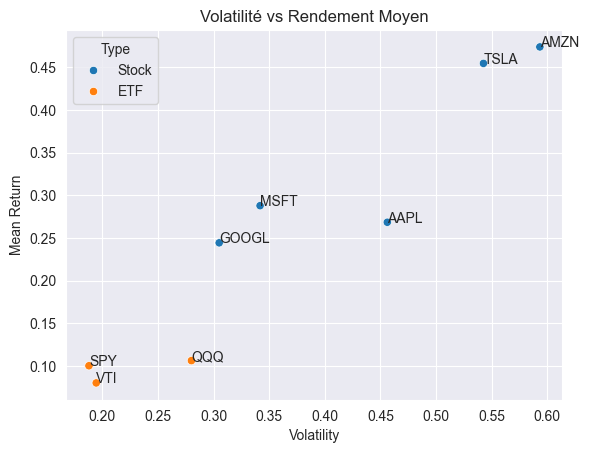

In [104]:
import pandas as pd

metrics_df: pd.DataFrame = pd.DataFrame({
    'Ticker': [t for t in analyzers],
    'Mean Return': [analyzers[t].get_metrics().mean_return for t in analyzers],
    'Volatility': [analyzers[t].get_metrics().volatility for t in analyzers],
    'Type': ['Stock' if t in selected_stocks else 'ETF' for t in analyzers]
})

sns.scatterplot(data=metrics_df, x='Volatility', y='Mean Return', hue='Type')
for i, row in metrics_df.iterrows():
    plt.annotate(row['Ticker'], (row['Volatility'], row['Mean Return']))
plt.title('Volatilité vs Rendement Moyen')
plt.show()


## Section 7 : Interprétation Économique

### Question 7.1 : Rédaction du rapport
**Énoncé** :  
Rédigez un rapport Markdown interprétant les résultats (performances, volatilité, implications), en utilisant des variables pour les moyennes de volatilité, et affichez-le avec display(Markdown(report)).


In [ ]:
# Insérez votre code ici


**Solution** :


In [105]:
from IPython.display import Markdown, display
import pandas as pd

report: str = '''
### Rapport d'Analyse Financière

- **Performances Clés** : Les actifs comme TSLA montrent des rendements élevés mais avec haute volatilité, tandis que les ETFs comme SPY offrent une stabilité.
- **Volatilité** : Les ETFs ont généralement une volatilité inférieure (moyenne {etfs_vol:.2f} vs {stocks_vol:.2f} pour stocks), confirmant leur rôle dans la diversification.
- **Implications Économiques** : Un beta élevé indique un risque systématique lié au marché ; pour un portefeuille, combiner stocks tech (hauts rendements) avec ETFs réduit le risque global. Dans un contexte de croissance tech post-COVID, les corrélations élevées suggèrent une sensibilité aux chocs sectoriels.
'''.format(etfs_vol=metrics_df[metrics_df['Type']=='ETF']['Volatility'].mean(),
           stocks_vol=metrics_df[metrics_df['Type']=='Stock']['Volatility'].mean())

display(Markdown(report))



### Rapport d'Analyse Financière

- **Performances Clés** : Les actifs comme TSLA montrent des rendements élevés mais avec haute volatilité, tandis que les ETFs comme SPY offrent une stabilité.
- **Volatilité** : Les ETFs ont généralement une volatilité inférieure (moyenne 0.22 vs 0.45 pour stocks), confirmant leur rôle dans la diversification.
- **Implications Économiques** : Un beta élevé indique un risque systématique lié au marché ; pour un portefeuille, combiner stocks tech (hauts rendements) avec ETFs réduit le risque global. Dans un contexte de croissance tech post-COVID, les corrélations élevées suggèrent une sensibilité aux chocs sectoriels.


## Section 8 : Analyse par Période Spécifique

### Question 8.1 : Définition de la fonction de filtre
**Énoncé** :  
Créez une fonction `filter_by_date(data, start_date, end_date)` qui filtre le DataFrame pour la plage de dates.


In [106]:
# Insérez votre code ici


**Solution** :


In [107]:
import pandas as pd
from typing import Optional

def filter_by_date(data: pd.DataFrame, start_date: str, end_date: str) -> pd.DataFrame:
    start: pd.Timestamp = pd.to_datetime(start_date)
    end: pd.Timestamp = pd.to_datetime(end_date)
    return data.loc[(data.index >= start) & (data.index <= end)]


### Question 8.2 : Filtrage des données
**Énoncé** :  
Filtrez `all_data` pour '2020-01-01' à '2023-12-31' et stockez dans `filtered_data`.


In [108]:
# Insérez votre code ici


**Solution** :


In [109]:
filtered_data: pd.DataFrame = filter_by_date(all_data, '2020-01-01', '2023-12-31')


### Question 8.3 : Analyse descriptive sur données filtrées
**Énoncé** :  
Calculez les stats descriptives sur 'adj_close' pour chaque ticker dans `filtered_data`, concaténez dans `filtered_all_stats`, et affichez-le.


In [110]:
# Insérez votre code ici


**Solution** :


In [111]:
filtered_stats_dict: dict[str, pd.DataFrame] = {}
for ticker in filtered_data.columns.levels[1]:
    df_ticker: pd.DataFrame = filtered_data.xs(ticker, level=1, axis=1)
    stats: pd.Series = df_ticker['adj_close'].describe()
    filtered_stats_dict[ticker] = stats.to_frame()

filtered_all_stats: pd.DataFrame = pd.concat(filtered_stats_dict, axis=1)
print('Stats filtrées :', filtered_all_stats)


Stats filtrées :              AAPL         AMZN        GOOGL        MSFT         QQQ  \
        adj_close    adj_close    adj_close   adj_close   adj_close   
count   63.000000    63.000000    63.000000   63.000000   63.000000   
mean   293.024354  1935.315071  1351.251112  164.017098  210.825332   
std     29.545279   112.659476   149.470414   13.532555   19.024394   
min    224.369995  1676.609985  1054.130005  135.419998  168.939987   
25%    273.439987  1872.825012  1215.030029  157.945000  193.981621   
50%    302.472137  1901.050049  1405.040039  162.835236  217.636215   
75%    317.765854  1991.894958  1471.070007  171.599678  222.855087   
max    327.200012  2170.219971  1524.869995  188.185989  236.476059   

              SPY        TSLA         VTI  
        adj_close   adj_close   adj_close  
count   63.000000   63.000000   63.000000  
mean   302.525590  619.605079  153.409583  
std     34.728218  146.731320   18.496119  
min    222.949997  361.220001  111.356850  
25%    2

### Question 8.4 : Comparaison des stats
**Énoncé** :  
Affichez la différence entre `all_stats` et `filtered_all_stats` pour comparer.


In [112]:
# Insérez votre code ici


**Solution** :


In [113]:
print('Comparaison stats complètes vs filtrées :', all_stats - filtered_all_stats)


Comparaison stats complètes vs filtrées :               AAPL         AMZN        GOOGL         MSFT          QQQ  \
         adj_close    adj_close    adj_close    adj_close    adj_close   
count  9846.000000  5695.000000  3869.000000  8521.000000  5238.000000   
mean   -262.447784 -1594.897491  -842.178929  -139.693584  -139.987662   
std      27.200995   410.480731   207.683044    16.837086    29.436280   
min    -224.214357 -1675.214152 -1004.074951  -135.362075  -151.418440   
25%    -272.522344 -1835.262512  -976.332581  -155.704394  -158.900723   
50%    -301.005983 -1819.450050 -1077.317307  -144.363124  -167.355606   
75%    -286.723480 -1657.604958  -712.567520  -145.990869  -125.275642   
max       0.000000     0.000000     0.000000     0.000000     0.000000   

               SPY         TSLA          VTI  
         adj_close    adj_close    adj_close  
count  6780.000000  2394.000000  4665.000000  
mean   -188.382324  -425.260553   -82.697084  
std      35.202347   -12.2817

### Question 8.5 : Ré-calcul des métriques sur données filtrées
**Énoncé** :  
Filtrez le benchmark si disponible, créez `filtered_analyzers` avec `AssetAnalyzer` pour chaque ticker sur `filtered_data`.


In [114]:
# Insérez votre code ici


**Solution** :


In [118]:
filtered_analyzers: dict[str, AssetAnalyzer] = {}
for ticker in filtered_data.columns.levels[1]:
    df_ticker: pd.DataFrame = filtered_data.xs(ticker, level=1, axis=1)
    filtered_analyzers[ticker] = AssetAnalyzer(df_ticker, ticker, benchmark_df=filter_by_date(benchmark, '2020-01-01', '2023-12-31') if benchmark is not None else None)

filtered_analyzers

{'AAPL': <__main__.AssetAnalyzer at 0x10a69fe00>,
 'AMZN': <__main__.AssetAnalyzer at 0x109147080>,
 'GOOGL': <__main__.AssetAnalyzer at 0x10b56c0e0>,
 'MSFT': <__main__.AssetAnalyzer at 0x10a69e3f0>,
 'QQQ': <__main__.AssetAnalyzer at 0x10a6a1010>,
 'SPY': <__main__.AssetAnalyzer at 0x108b2fe60>,
 'TSLA': <__main__.AssetAnalyzer at 0x1089ca180>,
 'VTI': <__main__.AssetAnalyzer at 0x1089cb7a0>}

### Question 8.6 : Affichage des métriques filtrées
**Énoncé** :  
Affichez les métriques pour chaque ticker sur les données filtrées.


In [119]:
# Insérez votre code ici


**Solution** :


In [120]:
for ticker, analyzer in filtered_analyzers.items():
    print(f'{ticker} (filtrée): {analyzer.get_metrics()}')


AAPL (filtrée): FinancialMetric(mean_return=np.float64(-0.6640572704690595), volatility=np.float64(0.6692338860027057), beta=np.float64(1.1663778460932677))
AMZN (filtrée): FinancialMetric(mean_return=np.float64(0.12272466230832073), volatility=np.float64(0.4558078695855685), beta=np.float64(0.6351715867399599))
GOOGL (filtrée): FinancialMetric(mean_return=np.float64(-0.7265833961343436), volatility=np.float64(0.5528676984953492), beta=np.float64(0.9424561271007664))
MSFT (filtrée): FinancialMetric(mean_return=np.float64(0.03153055121244022), volatility=np.float64(0.6995709362999272), beta=np.float64(1.212971009641703))
QQQ (filtrée): FinancialMetric(mean_return=np.float64(-0.5275202846398256), volatility=np.float64(0.5581195549479588), beta=np.float64(1.0008403567903428))
SPY (filtrée): FinancialMetric(mean_return=np.float64(-0.9487025051025663), volatility=np.float64(0.5545744625101323), beta=np.float64(1.0163934426229506))
TSLA (filtrée): FinancialMetric(mean_return=np.float64(1.174

### Question 8.7 : Discussion des implications
**Énoncé** :  
Ajoutez un commentaire ou Markdown discutant des implications (ex. : volatilité plus élevée pendant COVID).


In [ ]:
# Insérez votre code ici


**Solution** :


In [ ]:
# Discussion : Pendant la période COVID (2020-2023), la volatilité est souvent plus élevée due aux incertitudes économiques, illustrant l'impact des crises sur les marchés. Les betas pourraient augmenter, montrant un risque systématique accru ; cela souligne l'importance de la diversification en période turbulente.
